# U03.E06 — VAE, evaluación y Model Card

**Asignatura:** INF-8239 Ciencia de Datos II  
**Unidad:** 03 — Algoritmos y Características Generativas  
**Dataset:** Fashion-MNIST  
**Semilla aleatoria:** 42

## Objetivo

Entrenar y comparar un Autoencoder (AE) y un Variational Autoencoder (VAE), evaluar sus reconstrucciones, examinar muestras generadas e interpolaciones del espacio latente y documentar los costos, las limitaciones y las condiciones de reproducibilidad.

El entrenamiento se realiza mediante `scripts/train_ae_vae.py`. Las métricas de evaluación se calculan mediante `scripts/evaluate_ae_vae.py`.

In [5]:
from pathlib import Path
import json
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

ROOT = next(
    (
        p.resolve()
        for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "scripts" / "train_ae_vae.py").exists()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "No se encontró la raíz del proyecto. "
        "Abre el notebook desde la carpeta del proyecto."
    )

print(f"Directorio del proyecto: {ROOT}")
print(f"TensorFlow: {tf.__version__}")

archivos_requeridos = [
    "models/autoencoder.keras",
    "models/encoder.keras",
    "models/decoder.keras",
    "reports/training_metrics.json",
    "reports/ae_vae_panel.png",
    "reports/interpolation.png",
]

for archivo in archivos_requeridos:
    existe = (ROOT / archivo).exists()
    print(f"{archivo}: {'OK' if existe else 'FALTA'}")
    if not existe:
        raise FileNotFoundError(f"No se encontró: {archivo}")

Directorio del proyecto: C:\Users\raine\Desktop\Ciencias de Datos II\INF8239_U03_Generativos_Proyecto_Base_uv\INF8239_U03_Generativos_Proyecto_Base
TensorFlow: 2.21.0
models/autoencoder.keras: OK
models/encoder.keras: OK
models/decoder.keras: OK
reports/training_metrics.json: OK
reports/ae_vae_panel.png: OK
reports/interpolation.png: OK


## Protocolo experimental

Se utiliza Fashion-MNIST, compuesto por imágenes en escala de grises de 28 × 28 píxeles. Las imágenes se normalizan al intervalo [0, 1].

La ejecución registrada utiliza seis épocas para el AE y ocho para el VAE, con una dimensión latente de dos para el VAE y semilla 42.

Los modelos entrenados se guardan en `models/`. Las métricas y visualizaciones se guardan en `reports/`.

### Reproducción desde cero

Desde la raíz del proyecto, ejecutar estos comandos en PowerShell:

`uv run python scripts/train_ae_vae.py --epochs-ae 6 --epochs-vae 8`

`uv run python scripts/evaluate_ae_vae.py`

El primer comando vuelve a entrenar y sobrescribe los modelos guardados. No es necesario ejecutarlo para consultar los resultados existentes en este notebook.

In [6]:
subprocess.run(
    ["uv", "run", "python", "scripts/evaluate_ae_vae.py"],
    cwd=ROOT,
    check=True,
)

training = json.loads(
    (ROOT / "reports" / "training_metrics.json").read_text(encoding="utf-8")
)

evaluation = json.loads(
    (ROOT / "reports" / "evaluation_metrics.json").read_text(encoding="utf-8")
)

ae = evaluation["ae_reconstruction"]
vae = evaluation["vae_reconstruction"]

print("RESULTADOS DEL EXPERIMENTO")
print("=" * 65)
print(f"Semilla: {evaluation['seed']}")
print(f"Imágenes de prueba evaluadas: {evaluation['test_examples']}")
print(f"Imágenes de entrenamiento de referencia: "
      f"{evaluation['training_reference_examples']}")
print(f"Muestras generadas: {evaluation['generated_examples']}")

print("\nMÉTRICAS COMPARATIVAS")
print("-" * 65)
print(
    f"{'Modelo':<12} {'Entrenamiento (s)':>18} "
    f"{'MSE':>12} {'MAE':>12} {'Inferencia (ms/img)':>22}"
)

print(
    f"{'AE':<12} "
    f"{training['ae_train_seconds']:>18.4f} "
    f"{ae['mse']:>12.6f} "
    f"{ae['mae']:>12.6f} "
    f"{evaluation['ae_inference_ms_per_image']:>22.6f}"
)

print(
    f"{'VAE':<12} "
    f"{training['vae_train_seconds']:>18.4f} "
    f"{vae['mse']:>12.6f} "
    f"{vae['mae']:>12.6f} "
    f"{evaluation['vae_inference_ms_per_image']:>22.6f}"
)

print("\nCOMPLEJIDAD REGISTRADA")
print(f"Parámetros del AE: {training['ae_parameters']:,}")
print(f"Parámetros del decodificador VAE: "
      f"{training['decoder_parameters']:,}")
print("Nota: los parámetros del decodificador no representan "
      "el total del VAE.")

print("\nGENERACIÓN DEL VAE")
print(
    "Diversidad media por pares (MAE): "
    f"{evaluation['vae_generated_diversity']['mean_pairwise_mae']:.6f}"
)
print(
    "MAE medio frente al ejemplo de entrenamiento más cercano: "
    f"{evaluation['vae_generated_nearest_training']['mean_nearest_train_mae']:.6f}"
)
print(
    "MAE mínimo frente a un ejemplo de entrenamiento: "
    f"{evaluation['vae_generated_nearest_training']['min_nearest_train_mae']:.6f}"
)

RESULTADOS DEL EXPERIMENTO
Semilla: 42
Imágenes de prueba evaluadas: 1000
Imágenes de entrenamiento de referencia: 5000
Muestras generadas: 500

MÉTRICAS COMPARATIVAS
-----------------------------------------------------------------
Modelo        Entrenamiento (s)          MSE          MAE    Inferencia (ms/img)
AE                      13.9614     0.020676     0.082766               0.996356
VAE                     17.5315     0.033168     0.109321               0.256278

COMPLEJIDAD REGISTRADA
Parámetros del AE: 25,888
Parámetros del decodificador VAE: 101,520
Nota: los parámetros del decodificador no representan el total del VAE.

GENERACIÓN DEL VAE
Diversidad media por pares (MAE): 0.171836
MAE medio frente al ejemplo de entrenamiento más cercano: 0.066557
MAE mínimo frente a un ejemplo de entrenamiento: 0.032823


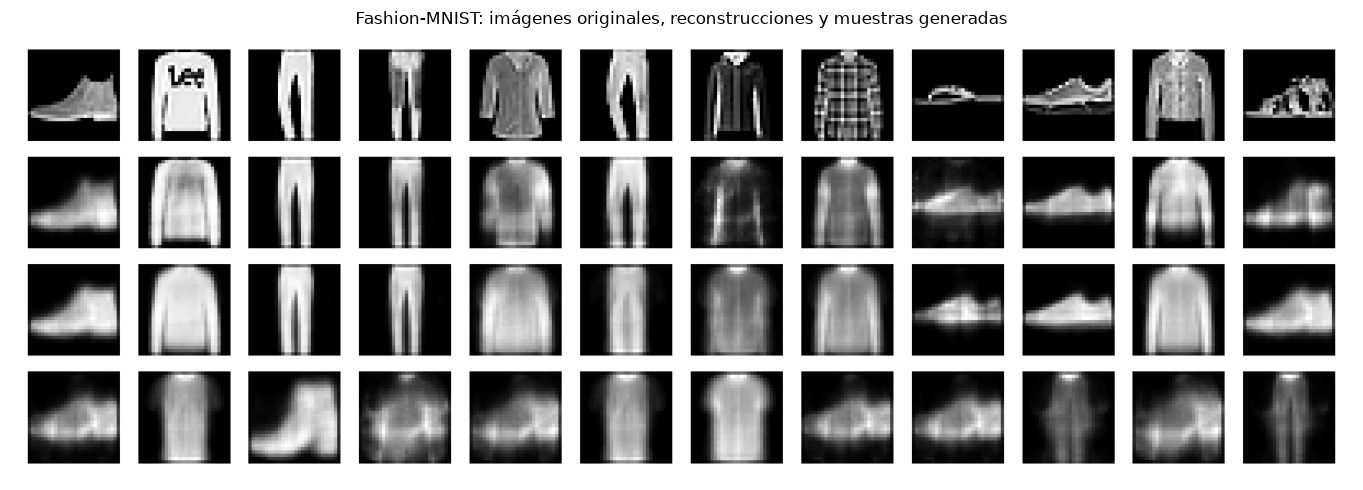

In [7]:
fig, ax = plt.subplots(figsize=(15, 5))

panel = plt.imread(ROOT / "reports" / "ae_vae_panel.png")
ax.imshow(panel)
ax.set_title(
    "Fashion-MNIST: imágenes originales, reconstrucciones "
    "y muestras generadas"
)
ax.axis("off")

plt.tight_layout()
plt.show()

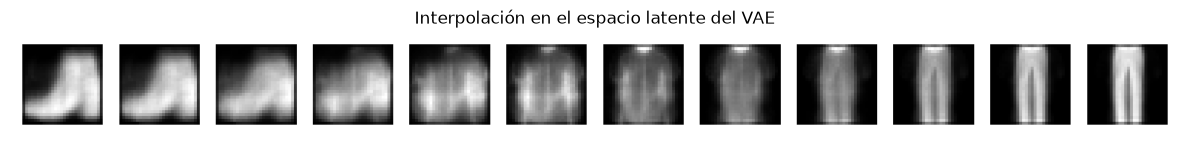

In [8]:
fig, ax = plt.subplots(figsize=(12, 3))

interpolation = plt.imread(
    ROOT / "reports" / "interpolation.png"
)

ax.imshow(interpolation)
ax.set_title("Interpolación en el espacio latente del VAE")
ax.axis("off")

plt.tight_layout()
plt.show()

## Conclusiones

En el experimento registrado, el Autoencoder obtuvo menores errores de reconstrucción que el VAE. El AE alcanzó un MSE de aproximadamente 0.020676, frente a 0.033168 del VAE, y un MAE de 0.082766, frente a 0.109321.

El tiempo de entrenamiento observado también fue menor para el AE. Por otro lado, el VAE permite estudiar la generación de muestras y las interpolaciones de su espacio latente, capacidades relevantes para los modelos generativos.

La diversidad y la distancia a los ejemplos de entrenamiento se interpretan como medidas exploratorias. Por sí solas no demuestran calidad visual, diversidad semántica ni ausencia de memorización.

### Limitaciones

- Los tiempos corresponden a una ejecución en CPU y pueden variar según el equipo.
- La evaluación cuantitativa utiliza una muestra de 1,000 imágenes de prueba y 5,000 imágenes de entrenamiento como referencia.
- Los errores de reconstrucción no describen completamente la calidad perceptual.
- La distancia en píxeles no basta para descartar memorización.
- No se realizó una medición directa de consumo eléctrico ni de emisiones de carbono.
- Los resultados se limitan a las arquitecturas, épocas y condiciones de este experimento.

### Decisión

Para reconstrucción de imágenes con menor error, los resultados favorecen al AE. Para estudiar muestreo e interpolación en un espacio latente, el VAE ofrece capacidades adicionales. La elección depende del objetivo de la aplicación.